For **Exercise 1**, you need to do three things:

1. Separate the tweet text (`X`) from the toxicity label (`y`).
2. Split the data into **80% training / 20% testing**.
3. Fit `CountVectorizer` on the training text and transform both training and testing text.

The important detail is **fit the vectorizer only on the training data** to avoid data leakage.

In [1]:
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split

[data source](https://cdn.alx-ai-tools.com/marimo/v2/data/Data/classification_sprint/toxicity_tweets_cleaned.csv)

In [3]:

tweets_df = pd.read_csv("../data/tweets.csv")
tweets_df.head()

,Tweet,Toxicity
0,i will beat a bitch ass tf,1
1,thomasnye1 my momma saw how the girls danced a...,1
2,user user dont forget his other incantation i...,0
3,isnt it sad how i keep thinking youll change ...,0
4,please tell this bitch im subbin her ik one of...,1


In [5]:
# Change the clumns names to lowercase
tweets_df.columns = [col.lower() for col in tweets_df.columns]

In [8]:
display(tweets_df.head(3))

,tweet,toxicity
0,i will beat a bitch ass tf,1
1,thomasnye1 my momma saw how the girls danced a...,1
2,user user dont forget his other incantation i...,0


In [7]:
# Separate features and target
X = tweets_df["tweet"]
y = tweets_df["toxicity"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Create CountVectorizer
vectorizer = CountVectorizer()

# Fit on training data and transform both sets
X_train_vectorized = vectorizer.fit_transform(X_train)
X_test_vectorized = vectorizer.transform(X_test)

# Check the results
print("Training shape:", X_train_vectorized.shape)
print("Testing shape:", X_test_vectorized.shape)

Training shape: (4539, 12628)
Testing shape: (1135, 12628)


### **Exercise 2**

Now we can build classifier models using the training data and assess their performance on the testing data.

Implement the following models: `Logistic Regression`, `Decision Tree`, `Support Vector Classification`, and `Nearest Neighbors`. Evaluate each model's performance using the following evaluation metrics: `accuracy`, `precision`, `recall`, and `F1 score`. Note: Running these models might take a few minutes, depending on the complexity chosen.

In addition to this, calculate the confusion matrix for each of our models.

What do these results tell us about our models?

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

#### __Creates the Models__

In [11]:
logreg = LogisticRegression(
    max_iter=1000,
    random_state=42
)

tree = DecisionTreeClassifier(
    random_state=42
)

svc = SVC(
    kernel="linear",
    random_state=42
)

knn = KNeighborsClassifier(
    n_neighbors=5
)

#### **Train the Models**

In [12]:
models = {
    "Logistic Regression": logreg,
    "Decision Tree": tree,
    "SVM": svc,
    "KNN": knn
}

for name, model in models.items():
    model.fit(X_train_vectorized, y_train)

#### **Evaluate the Models**

In [13]:
results = []

for name, model in models.items():

    # Make predictions
    y_pred = model.predict(X_test_vectorized)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.910132,0.949640,0.830189,0.885906
1,Decision Tree,0.918062,0.928571,0.872117,0.899459
2,SVM,0.915419,0.935927,0.857442,0.894967
3,KNN,0.785022,0.737271,0.758910,0.747934


#### __Display the confusion matrix__

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

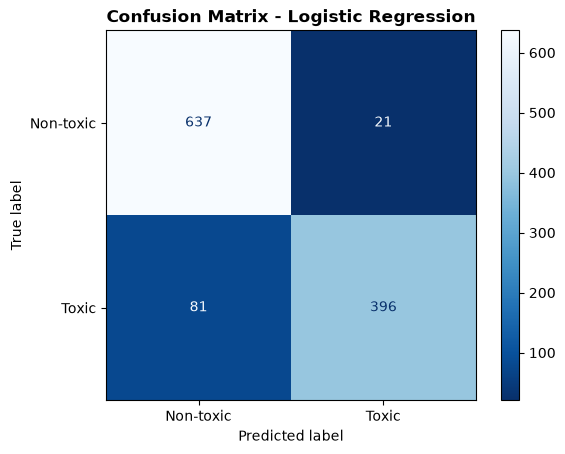

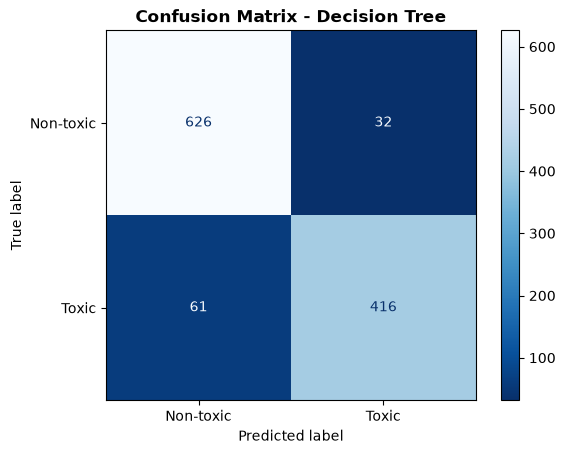

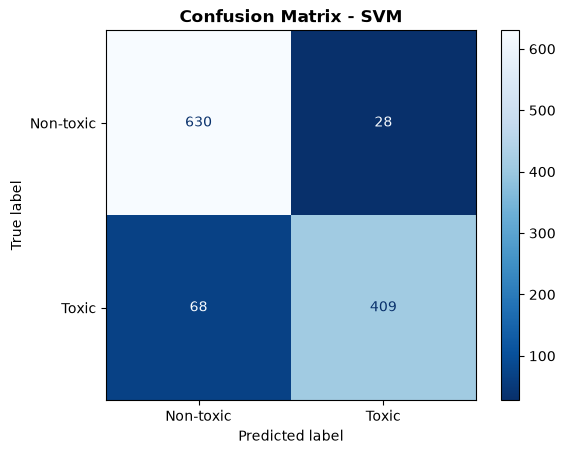

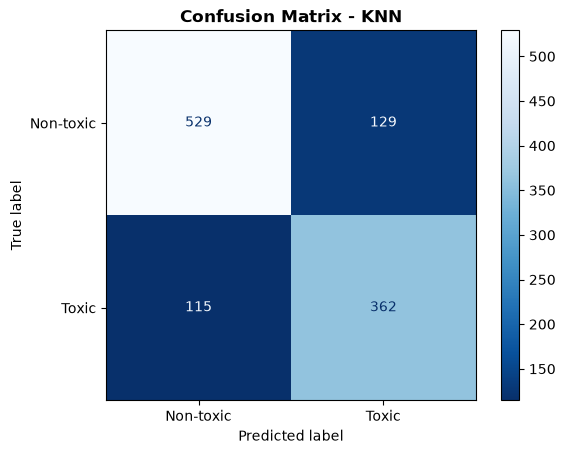

In [ ]:
for model_name, model in models.items():

    y_pred = model.predict(X_test_vectorized)
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Non-toxic", "Toxic"],
        cmap = "Blues_r"
    )

    plt.title(f"Confusion Matrix - {model_name}", fontweight="bold")
    plt.show()

**Model Comparison & Performance Breakdown**

| Metric / Model | Logistic Regression | Decision Tree | SVM | KNN |
| --- | --- | --- | --- | --- |
| **True Negatives ($TN$)** | 637 | 626 | 630 | 529 |
| **False Positives ($FP$)** | 21 | 32 | 28 | 129 |
| **False Negatives ($FN$)** | 81 | 61 | 68 | 115 |
| **True Positives ($TP$)** | 396 | 416 | 409 | 362 |
| **Total Samples** | 1,135 | 1,135 | 1,135 | 1,135 |
| **Accuracy** | **91.01%** | 91.81% | **91.54%** | 78.50% |
| **Precision (Toxic)** | **94.96%** | 92.86% | **93.59%** | 73.73% |
| **Recall / Sensitivity** | 83.02% | **87.21%** | **85.74%** | 75.89% |
| **F1-Score (Toxic)** | 88.60% | **89.95%** | **89.49%** | 74.79% |

---

**Key Takeaways**

* **Highest Overall Performance:** **Decision Tree** achieves the highest overall **F1-Score (89.95%)**, **Accuracy (91.81%)**, and **Recall (87.21%)**, making it effective at capturing toxic instances while keeping false negatives low.
* **Highest Precision:** **Logistic Regression** minimizes False Positives best ($FP = 21$), yielding the cleanest positive predictions with **94.96% Precision**.
* **Balanced Alternative:** **SVM** offers a middle ground, yielding strong precision (93.59%) and recall (85.74%) with minimal degradation across metrics.
* **Weakest Performer:** **KNN** lags significantly across all evaluation axes ($78.50\%$ accuracy), suffering high false-positive rates ($FP = 129$).

### **Exercise 3**
In addition to the performance evaluation based on metrics and confusion matrices, cross-validation scores provide further insights into the robustness and generalisation capabilities of classifier models.

After evaluating the performance of our classifier models, we want to determine the best model based on their cross-validation scores.

Perform 5-fold cross-validation for each classifier model using the training data and print the `mean cross-validation score`.

**Note**: This code should take a few minutes to run

### __Cross Validation__

In [21]:
from sklearn.model_selection import cross_val_score

In [24]:
models = {
    "Logistic Regression": logreg,
    "Decision Tree": tree,
    "SVM": svc,
    "KNN": knn
}

for name, model in models.items():
    cv_scores = cross_val_score(
        model,
        X_train_vectorized,
        y_train,
        cv=5,
        scoring="accuracy"
    )
    print(f"\n{name}")
    print(f"Fold scores: {cv_scores}")
    print(f"Mean CV score: {cv_scores.mean():.4f}")


Logistic Regression
Fold scores: [0.90638767 0.91079295 0.90528634 0.89867841 0.90077178]
Mean CV score: 0.9044

Decision Tree
Fold scores: [0.90088106 0.88215859 0.89757709 0.89867841 0.90297685]
Mean CV score: 0.8965

SVM
Fold scores: [0.91189427 0.89977974 0.91079295 0.90528634 0.90518192]
Mean CV score: 0.9066

KNN
Fold scores: [0.79955947 0.78414097 0.78303965 0.79295154 0.75964719]
Mean CV score: 0.7839


The **5-fold cross-validation** results show that SVM achieved the highest mean accuracy of **90.66%**, making it the best-performing classifier based on cross-validation. Logistic Regression performed very similarly, with a mean score of **90.44%**, only 0.22 percentage points below SVM. Decision Tree achieved a mean score of **89.65%**, while KNN performed substantially worse at **78.39%**. Overall, SVM and Logistic Regression appear to be the strongest models for this text-classification task. Although SVM has the highest cross-validation score, the very small difference between SVM and Logistic Regression suggests that both models provide competitive performance.